In [142]:
from pathlib import Path

chart_folder = Path("../outputs/charts")
chart_folder.mkdir(parents=True, exist_ok=True)

In [143]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_excel(r"D:\data science week 1\data\raw\Online Retail.xlsx")

# Display first 5 rows
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [144]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (541909, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [145]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [146]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [147]:
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [148]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 5268


In [149]:
# Create a copy of original dataset
df_clean = df.copy()

print("Original Dataset:", df.shape)
print("Working Dataset:", df_clean.shape)

Original Dataset: (541909, 8)
Working Dataset: (541909, 8)


In [150]:
# Calculate missing values
missing = df_clean.isnull().sum()

# Calculate missing percentage
missing_percent = (missing / len(df_clean)) * 100

missing_report = pd.DataFrame({
    "Missing Values": missing,
    "Missing Percentage": missing_percent
})

missing_report

,Missing Values,Missing Percentage
InvoiceNo,0,0.000000
StockCode,0,0.000000
Description,1454,0.268311
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
CustomerID,135080,24.926694
Country,0,0.000000


In [151]:
print("Duplicates before cleaning:", df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates()

print("Duplicates after cleaning:", df_clean.duplicated().sum())

Duplicates before cleaning: 5268
Duplicates after cleaning: 0


In [152]:
# Check missing values
print(df_clean.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64


In [153]:
df_clean = df_clean.dropna(subset=["Description"])

print("Remaining missing values:")
print(df_clean.isnull().sum())

Remaining missing values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     133583
Country             0
dtype: int64


In [154]:
# Convert InvoiceDate into datetime
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"]
)

# Convert CustomerID to nullable integer
df_clean["CustomerID"] = df_clean["CustomerID"].astype("Int64")

print(df_clean.dtypes)

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID              Int64
Country                object
dtype: object


In [155]:
sales_df = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0) &
    (~df_clean["InvoiceNo"].astype(str).str.startswith("C"))
].copy()

print("Clean Sales Records:", sales_df.shape)

Clean Sales Records: (524878, 8)


In [156]:
top_products = (
    sales_df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64


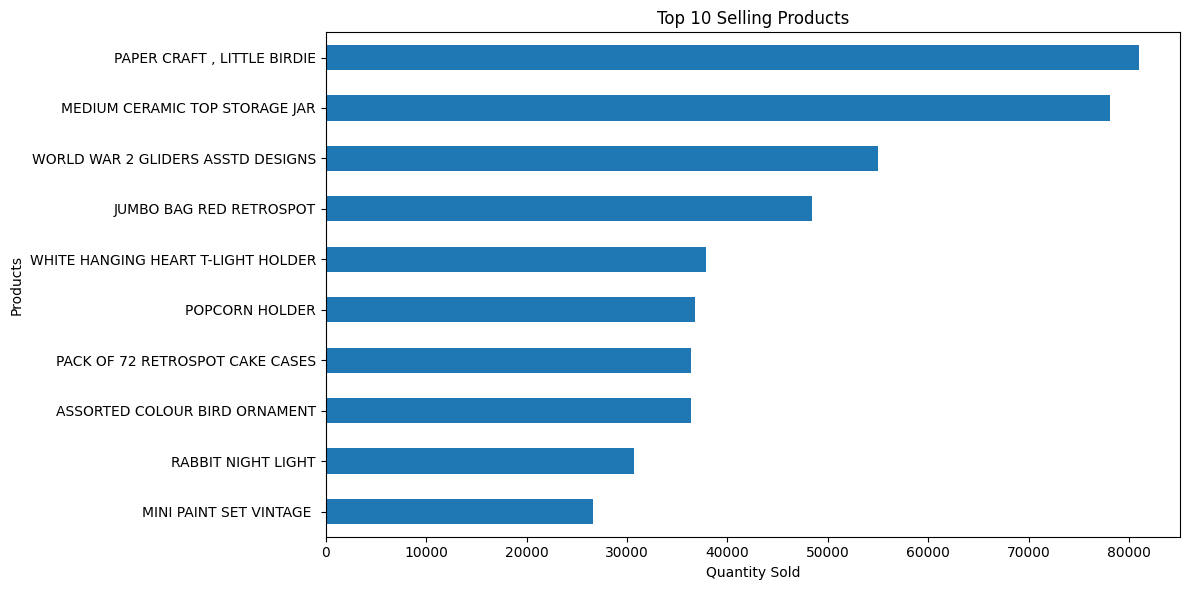

In [157]:
plt.figure(figsize=(12, 6))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Selling Products")
plt.xlabel("Quantity Sold")
plt.ylabel("Products")

plt.tight_layout()
plt.show()

<Figure size 1200x600 with 0 Axes>

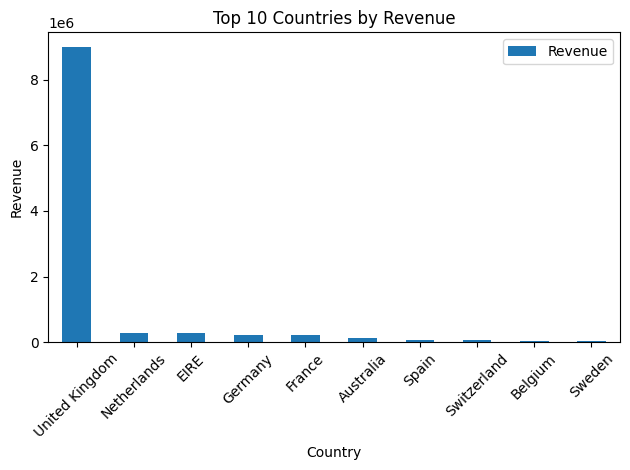

In [158]:
plt.figure(figsize=(12, 6))

country_sales.plot(kind="bar")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Country")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [159]:
sales_df["Revenue"] = sales_df["Quantity"] * sales_df["UnitPrice"]

print("Revenue column created successfully!")
print(sales_df[["Quantity", "UnitPrice", "Revenue"]].head())

Revenue column created successfully!
   Quantity  UnitPrice  Revenue
0         6       2.55    15.30
1         6       3.39    20.34
2         8       2.75    22.00
3         6       3.39    20.34
4         6       3.39    20.34


In [160]:
country_sales = (
    sales_df.groupby("Country")
    .agg({"Revenue": "sum"})
    .sort_values(by="Revenue", ascending=False)
    .head(10)
)

print("Top 10 Countries by Revenue:")
print(country_sales)

Top 10 Countries by Revenue:
                    Revenue
Country                    
United Kingdom  9001744.094
Netherlands      285446.340
EIRE             283140.520
Germany          228678.400
France           209625.370
Australia        138453.810
Spain             61558.560
Switzerland       57067.600
Belgium           41196.340
Sweden            38367.830


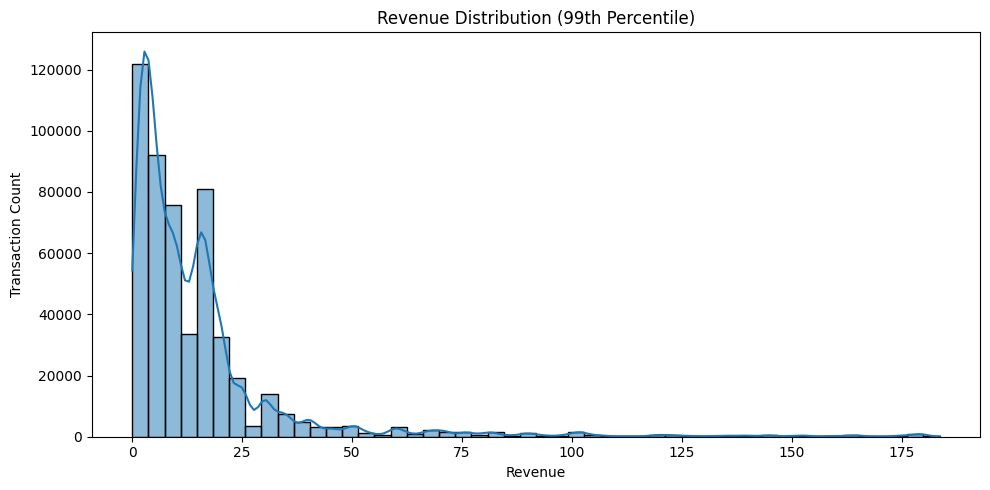

In [161]:
# Revenue distribution - 99th percentile view

plt.figure(figsize=(10, 5))

upper_limit = sales_df["Revenue"].quantile(0.99)

sns.histplot(
    sales_df[
        sales_df["Revenue"] <= upper_limit
    ]["Revenue"],
    bins=50,
    kde=True
)

plt.title("Revenue Distribution (99th Percentile)")
plt.xlabel("Revenue")
plt.ylabel("Transaction Count")

plt.tight_layout()
plt.savefig(
    "../outputs/charts/revenue_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [162]:
# Check unusually large quantities

sales_df.nlargest(
    10, "Quantity"
)[
    ["InvoiceNo", "Description",
     "Quantity", "UnitPrice", "Revenue"]
]

,InvoiceNo,Description,Quantity,UnitPrice,Revenue
540421,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60
61619,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60
421632,573008,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,1008.00
206121,554868,SMALL POPCORN HOLDER,4300,0.72,3096.00
97432,544612,EMPIRE DESIGN ROSETTE,3906,0.82,3202.92
270885,560599,ESSENTIAL BALM 3.5g TIN IN ENVELOPE,3186,0.06,191.16
52711,540815,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40
160546,550461,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2.10,6539.40
433788,573995,SMALL CHINESE STYLE SCISSOR,3000,0.32,960.00
4945,536830,WORLD WAR 2 GLIDERS ASSTD DESIGNS,2880,0.18,518.40


In [163]:
# Find the specific unusual transaction

sales_df[
    sales_df["Quantity"] == 80995
]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446,United Kingdom,168469.6


In [164]:
# Check missing Customer IDs

print(
    "Missing Customer IDs:",
    sales_df["CustomerID"].isnull().sum()
)

print(
    "Total Records:",
    len(sales_df)
)

Missing Customer IDs: 132186
Total Records: 524878


In [165]:
# Create customer analysis dataset

customer_df = sales_df.dropna(
    subset=["CustomerID"]
).copy()

print("Original Sales Records:", len(sales_df))

print("Customer Analysis Records:", len(customer_df))

print(
    "Missing Customer IDs:",
    customer_df["CustomerID"].isnull().sum()
)

Original Sales Records: 524878
Customer Analysis Records: 392692
Missing Customer IDs: 0


In [166]:
# Customer Revenue Analysis

customer_revenue = (
    customer_df.groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Customers by Revenue")

print(customer_revenue.head(10))

Top 10 Customers by Revenue
CustomerID
14646    280206.02
18102    259657.30
17450    194390.79
16446    168472.50
14911    143711.17
12415    124914.53
14156    117210.08
17511     91062.38
16029     80850.84
12346     77183.60
Name: Revenue, dtype: float64


In [167]:
# Save final cleaned dataset

sales_df.to_csv(
    "../data/cleaned/online_retail_cleaned.csv",
    index=False
)

print("Final cleaned dataset saved successfully!")

Final cleaned dataset saved successfully!


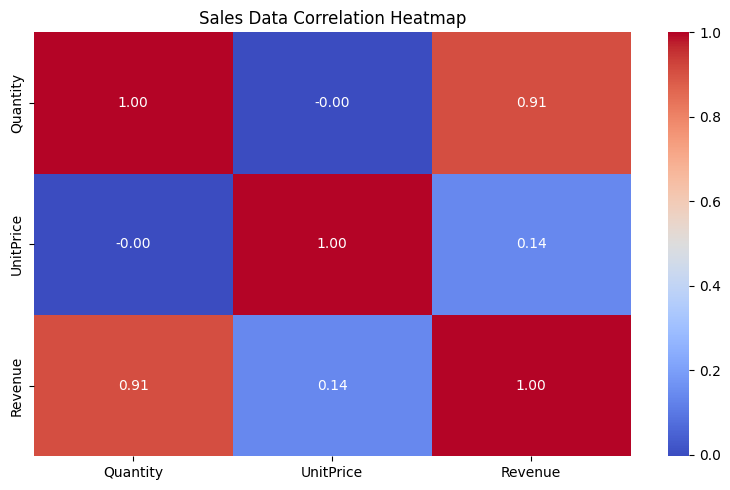

In [168]:
# Correlation Analysis

correlation = sales_df[
    ["Quantity", "UnitPrice", "Revenue"]
].corr()

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Sales Data Correlation Heatmap")

plt.tight_layout()
plt.savefig(
    "../outputs/charts/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

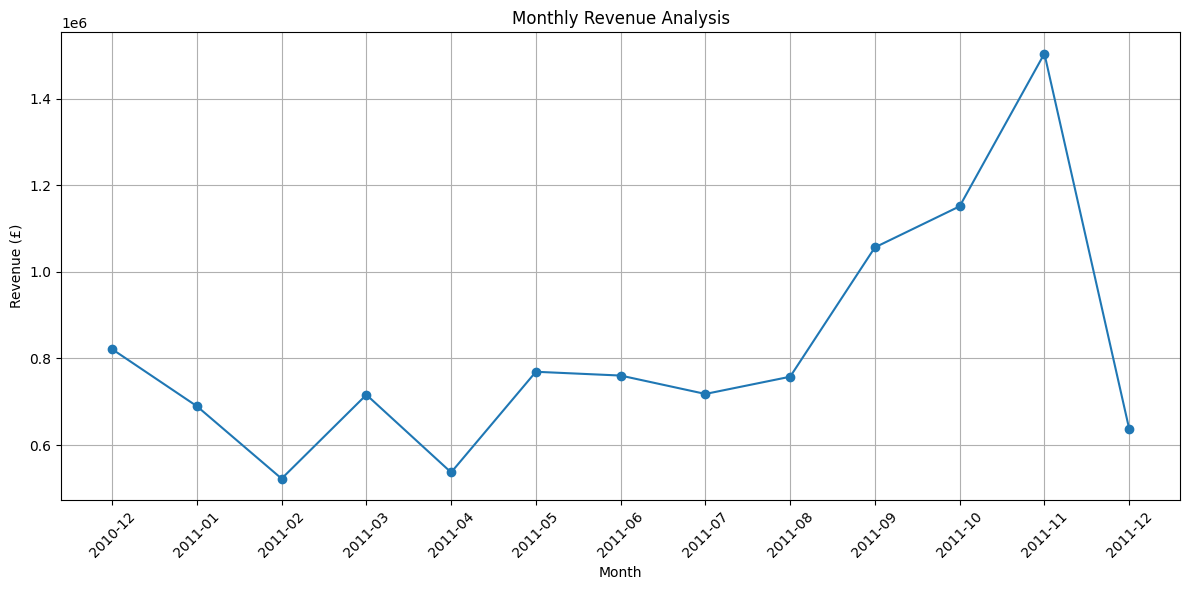

Monthly revenue chart saved successfully!


In [169]:
# Calculate monthly revenue
monthly_revenue = (
    sales_df.groupby(sales_df["InvoiceDate"].dt.to_period("M"))["Revenue"]
    .sum()
)

# Create monthly revenue chart
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker="o"
)

plt.title("Monthly Revenue Analysis")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

# Save chart
plt.savefig(
    "../outputs/charts/monthly_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Monthly revenue chart saved successfully!")

In [170]:
# %% [1] KPI SUMMARY TABLE
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

Path("../outputs/charts").mkdir(parents=True, exist_ok=True)
Path("../outputs/dashboard").mkdir(parents=True, exist_ok=True)

total_revenue = sales_df["Revenue"].sum()
total_orders = sales_df["InvoiceNo"].nunique()
avg_order_value = total_revenue / total_orders
total_units = sales_df["Quantity"].sum()

product_revenue = sales_df.groupby("Description")["Revenue"].sum().sort_values(ascending=False)
product_units = sales_df.groupby("Description")["Quantity"].sum().sort_values(ascending=False)

kpi_table = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Orders",
        "Average Order Value",
        "Total Units Sold",
        "Top Revenue-Generating Product",
        "Top-Selling Product (by units)",
        "Top Country by Revenue",
    ],
    "Value": [
        f"£{total_revenue:,.2f}",
        f"{total_orders:,}",
        f"£{avg_order_value:,.2f}",
        f"{total_units:,}",
        product_revenue.index[0],
        product_units.index[0],
        sales_df.groupby("Country")["Revenue"].sum().idxmax(),
    ],
    "Meaning": [
        "Sum of Quantity x UnitPrice for valid sales",
        "Unique invoices after removing cancellations",
        "Total revenue divided by total orders",
        "Sum of quantities sold",
        "Product with the highest revenue",
        "Product with the most units sold",
        "Country contributing the most revenue",
    ],
})



In [171]:
kpi_table.to_csv("../outputs/kpi_summary.csv", index=False)
kpi_table

,KPI,Value,Meaning
0,Total Revenue,"£10,642,110.80",Sum of Quantity x UnitPrice for valid sales
1,Total Orders,"19,960",Unique invoices after removing cancellations
2,Average Order Value,£533.17,Total revenue divided by total orders
3,Total Units Sold,"5,572,420",Sum of quantities sold
4,Top Revenue-Generating Product,DOTCOM POSTAGE,Product with the highest revenue
5,Top-Selling Product (by units),"PAPER CRAFT , LITTLE BIRDIE",Product with the most units sold
6,Top Country by Revenue,United Kingdom,Country contributing the most revenue


In [172]:
# %% [2] REPEAT CUSTOMER SHARE OF REVENUE (customer insight)
orders_per_customer = customer_df.groupby("CustomerID")["InvoiceNo"].nunique()
revenue_per_customer = customer_df.groupby("CustomerID")["Revenue"].sum()

repeat_ids = orders_per_customer[orders_per_customer > 1].index
repeat_share_customers = len(repeat_ids) / len(orders_per_customer) * 100
repeat_share_revenue = revenue_per_customer.loc[repeat_ids].sum() / revenue_per_customer.sum() * 100

print(f"Repeat customers: {repeat_share_customers:.1f}% of identified customers")
print(f"Revenue from repeat customers: {repeat_share_revenue:.1f}% of identified-customer revenue")




Repeat customers: 65.6% of identified customers
Revenue from repeat customers: 93.1% of identified-customer revenue


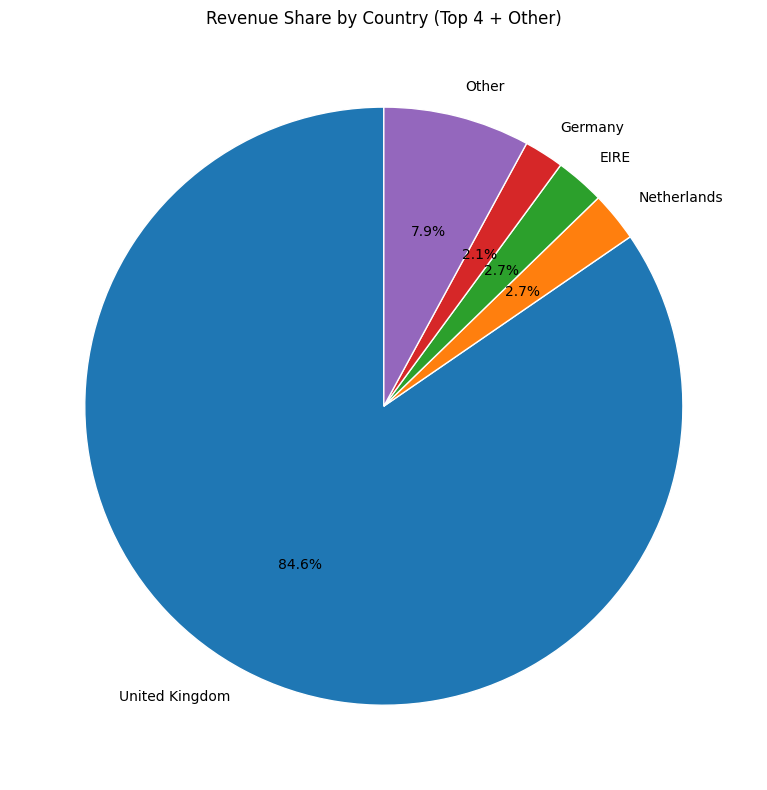

In [173]:
# %% [3] PIE CHART - revenue share by country (top 4 + Other)
country_rev = sales_df.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
pie_data = country_rev.head(4).copy()
pie_data["Other"] = country_rev.iloc[4:].sum()

plt.figure(figsize=(8, 8))
plt.pie(
    pie_data.values,
    labels=pie_data.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white"},
)
plt.title("Revenue Share by Country (Top 4 + Other)")
plt.tight_layout()
plt.savefig("../outputs/charts/revenue-share-by-country-pie.png", dpi=300, bbox_inches="tight")
plt.show()

